# Part 3a. Bag of Words

Bag of Words represents each review by a term-frequency vector: the count of each vocabulary word. Order is ignored. English stop-words are removed. Tokens are letter sequences of length at least 2. A word must appear in at least 5 reviews and in at most 85% of reviews. The vocabulary is capped at 3,000 terms.

The output of this notebook is the term-frequency matrix, its sparsity, the most common terms, and an excerpt of the matrix.

## Setup and cleaning

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data" / "airlines_reviews.csv").exists():
    ROOT = Path(r"C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning")

DATA_PATH = ROOT / "data" / "airlines_reviews.csv"
FIG = ROOT / "figures" / "bow"
OUT = ROOT / "outputs" / "bow"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

RATING_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages",
    "Inflight Entertainment", "Value For Money", "Overall Rating",
]
SERVICE_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages", "Inflight Entertainment",
]
RANDOM_STATE = 42


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def silhouette_safe(X, labels):
    # Silhouette on non-noise points. NaN when a partition is not valid.
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) < 3 or len(np.unique(y)) < 2:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    if counts.min() < 2:
        return np.nan
    return float(silhouette_score(X[mask], y, n_jobs=-1))


print("Question folder:", FIG.parent.name + "/" + FIG.name)
print("Data file:", DATA_PATH)

Question folder: figures/bow
Data file: C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning\data\airlines_reviews.csv


In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
text_cols = [col for col in df.columns if pd.api.types.is_string_dtype(df[col])]
for col in text_cols:
    df[col] = df[col].str.replace("\xa0", " ", regex=False).str.strip()

verified_map = {
    "True": "True", "False": "False", "*Unverified*": "False", "NotVerified": "False",
}
n_verified_fixed = int((~df["Verified"].isin(["True", "False"])).sum())
df["Verified"] = df["Verified"].map(verified_map).fillna("False")

ife = df["Inflight Entertainment"]
n_ife_zero = int((ife == 0).sum())
ife_median = float(ife[ife > 0].median())
df.loc[ife == 0, "Inflight Entertainment"] = ife_median

n_dups = int(df["Reviews"].duplicated().sum())
df = df.drop_duplicates(subset=["Reviews"]).reset_index(drop=True)

df["Month Flown Date"] = pd.to_datetime(df["Month Flown"], format="%B %Y")
df["Year Flown"] = df["Month Flown Date"].dt.year
df["Year Bin"] = pd.cut(
    df["Year Flown"],
    bins=[2012, 2016, 2019, 2021, 2025],
    labels=["2013-2016", "2017-2019", "2020-2021", "2022-2024"],
).astype(str)
df["Review Length"] = df["Reviews"].str.len()

print(f"Rows before cleaning: {len(raw):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Verified flags corrected: {n_verified_fixed}")
print(f"Inflight Entertainment zeros imputed with median {ife_median:.0f}: {n_ife_zero}")
print(f"Duplicate reviews removed: {n_dups}")

Rows before cleaning: 8,100
Rows after cleaning:  8,098
Verified flags corrected: 3
Inflight Entertainment zeros imputed with median 4: 1
Duplicate reviews removed: 2


In [3]:
def clean_text(text):
    text = text.replace("\xa0", " ").lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["review_clean"] = df["Reviews"].map(clean_text)
print("Empty reviews after cleaning:", int((df["review_clean"] == "").sum()))
print("Example:", df.loc[0, "review_clean"][:350])
TOKEN = r"(?u)\b[a-zA-Z]{2,}\b"
VECTOR_KW = dict(stop_words="english", token_pattern=TOKEN, min_df=5, max_df=0.85, max_features=3000)

Empty reviews after cleaning: 0
Example: flight was amazing the crew onboard this flight were very welcoming and gave a good atmosphere the crew serving my aisle goes by the initial g she was very kind helpful gave my mom a bday cake for a late celebration even though it was just a hr min flight seat is well sanitized legroom is spacious ife onboard has many variety of shows music etc bat


## Term-frequency matrix

Term-frequency matrix shape: (8098, 3000)
Stored counts: 397,767
Sparsity: 98.36%
Twenty most frequent terms:


,term,count
0,flight,14803
1,service,6494
2,time,4601
3,food,4361
4,seat,4191
5,good,4053
6,crew,3776
7,airlines,3741
8,staff,3676
9,class,3605


Term-frequency excerpt: first 8 reviews, 12 most common terms


,review,flight,service,time,food,seat,good,crew,airlines,staff,class,cabin,seats
0,0,4,0,0,1,1,1,3,0,0,0,0,0
1,1,1,0,0,0,2,0,0,0,0,0,0,1
2,2,0,0,0,1,0,0,0,0,1,0,0,0
3,3,4,0,0,1,0,1,2,0,0,3,3,0
4,4,0,1,0,0,1,1,1,0,0,0,1,0
5,5,5,1,0,0,3,0,0,0,0,0,0,0
6,6,1,1,1,0,3,0,1,1,1,0,0,0
7,7,1,0,1,0,0,0,0,0,0,0,0,0


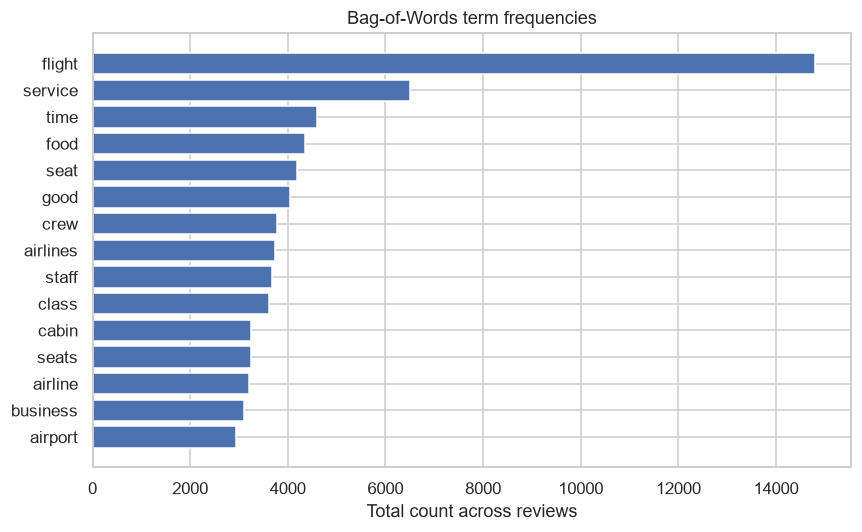

In [4]:
bow = CountVectorizer(**VECTOR_KW)
X_bow = bow.fit_transform(df["review_clean"])
terms = np.array(bow.get_feature_names_out())
totals = np.asarray(X_bow.sum(axis=0)).ravel()
sparsity = 1 - X_bow.nnz / np.prod(X_bow.shape)
print(f"Term-frequency matrix shape: {X_bow.shape}")
print(f"Stored counts: {X_bow.nnz:,}")
print(f"Sparsity: {sparsity:.2%}")

top = pd.DataFrame({"term": terms, "count": totals}).sort_values("count", ascending=False).head(20)
print("Twenty most frequent terms:")
display(top.reset_index(drop=True))
top.to_csv(OUT / "bow_top_terms.csv", index=False)

top12 = top["term"].head(12).tolist()
col_index = [int(np.where(terms == t)[0][0]) for t in top12]
excerpt = pd.DataFrame(X_bow[:8, col_index].toarray().astype(int), columns=top12)
excerpt.insert(0, "review", np.arange(8))
print("Term-frequency excerpt: first 8 reviews, 12 most common terms")
display(excerpt)
excerpt.to_csv(OUT / "bow_matrix_excerpt.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
plot_df = top.head(15).iloc[::-1]
ax.barh(plot_df["term"], plot_df["count"], color="#4C72B0")
ax.set_xlabel("Total count across reviews")
ax.set_title("Bag-of-Words term frequencies")
save_fig(fig, "bow_top_terms.png")

## Part 3a answer

The printed shape is the term-frequency matrix: one row per review, one column per vocabulary term, and the cell value is the raw count. Most cells are zero, which is the sparsity figure. The excerpt is a readable corner of that matrix.